# E1: calibrated SVM probabilities

Use the validation-selected SVM from each completed feature study, with the
91-feature SVM as a reference. Read feature counts and exact columns from the
saved artifacts for the 40,000-clip dataset with source loudness preserved.

The current completed studies give these original balanced accuracies:

| SVM features | Validation | Test |
| --- | --- | --- |
| 39 (selected from 39) | 95.95% | 96.15% |
| 65 (selected from 91) | 97.13% | 97.36% |
| 91 (reference) | 97.02% | 97.31% |

Fit sigmoid calibration with five speaker-separated folds on training plus validation.
Keep saved feature columns fixed and fit the scaler inside each fold.
Save separate calibrated files and check decision scores against the originals.
Test clips stay out of fitting. **Run All includes test evaluation.**

Use Singapore (`1`) when `p_singapore >= 0.50`; otherwise Non-Singapore (`0`).
This is exploratory: feature selection used development labels, and test speakers
were used before. Sources and prompts differ between classes. High probability
does not detect unfamiliar audio.

Run both feature studies through test evaluation first. Read
`outputs/e1_feature_study_accent_40000_no_loudness_norm/` and save separate
artifacts in its `svm_calibrated_probability_testing/` subdirectory. Reuse the
shared 39/91-feature caches and speaker assignments: 20,000 clips per class,
33,881 development clips and 6,119 test clips. No audio decoding or extraction is
needed. Verify original test scores before calibration; do not use them to select
settings. Old notebook outputs are cleared; the new calibration has not been run.


In [1]:
from pathlib import Path
import hashlib
import json
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
STUDY_DIR = PROJECT_ROOT / 'outputs/e1_feature_study_accent_40000_no_loudness_norm'
RESULTS_DIR = STUDY_DIR / 'svm_calibrated_probability_testing'

EXPECTED_CLIPS = 40_000
EXPECTED_CLASS_COUNTS = {0: 20_000, 1: 20_000}
RANDOM_SEED = 42
CV_FOLDS = 5
THRESHOLD = 0.50  # Fixed threshold.


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


study_paths = {39: STUDY_DIR / 'results/study_results.joblib',
               91: STUDY_DIR / 'results_91/study_results.joblib'}
required_paths = [STUDY_DIR / name for name in
    ['speaker_splits.csv', 'current_cache_metadata.json',
     'acoustic_features_39.npz', 'acoustic_features_91.npz']]
required_paths.extend(study_paths.values())
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError('Complete both updated E1 feature studies first. Missing: ' + ', '.join(missing))

# Load the same clips and splits as both studies.
snapshot = pd.read_csv(STUDY_DIR / 'speaker_splits.csv', index_col='clip_id', keep_default_na=False,
    dtype={column: str for column in ['clip_id', 'speaker_group', 'split', 'source',
                                     'source_clip_id', 'speaker_id', 'accent_group']})
if snapshot.empty or not snapshot.index.is_unique or snapshot.isna().any().any():
    raise ValueError('Invalid saved split.')
if len(snapshot) != EXPECTED_CLIPS:
    raise ValueError(f'Expected {EXPECTED_CLIPS:,} saved clips; found {len(snapshot):,}.')
if snapshot['label'].value_counts().to_dict() != EXPECTED_CLASS_COUNTS:
    raise ValueError('Expected 20,000 saved clips per class.')
if not snapshot.loc[snapshot['label'].eq(1), 'source'].eq('mnsc').all():
    raise ValueError('Expected only MNSC positives, as in the E1 studies.')
if not set(snapshot['split']) == {'train', 'validation', 'test'}:
    raise ValueError('Unexpected split name.')
if (snapshot.groupby('speaker_group')['split'].nunique() > 1).any():
    raise ValueError('Speaker overlap between splits.')
if (snapshot.groupby('speaker_group')['label'].nunique() > 1).any():
    raise ValueError('A speaker has mixed labels.')
dataset_id = digest(snapshot.reset_index().to_dict(orient='records'))

with np.load(STUDY_DIR / 'acoustic_features_39.npz', allow_pickle=False) as cache:
    base_features = cache['features'].copy()
    base_feature_names = cache['feature_names'].tolist()
    base_cache_id = str(cache['cache_id'].item())
    y, groups, clip_ids = (cache[key].copy() for key in ('labels', 'groups', 'clip_ids'))
base_metadata = json.loads((STUDY_DIR / 'current_cache_metadata.json').read_text())
if digest(base_metadata) != base_cache_id or base_metadata['dataset_id'] != dataset_id:
    raise ValueError('Base cache identity differs from the saved study.')
source_preprocessing = base_metadata.get('source_preprocessing', {})
if (source_preprocessing.get('loudness_normalization') is not False
        or source_preprocessing.get('peak_scaling') is not False
        or source_preprocessing.get('audio_format') != 'WAV/FLOAT'
        or source_preprocessing.get('sample_rate') != 16000
        or base_metadata['settings'].get('waveform_transform') != 'decode_float32_wav_only'
        or base_metadata['settings'].get('loudness_normalization') is not False
        or base_metadata['settings'].get('peak_scaling') is not False
        or base_metadata.get('loader_sha256') != file_hash(PROJECT_ROOT / 'scripts/unnormalized_dataset.py')):
    raise ValueError('Expected the current source-loudness-preserving WAV feature caches.')
if not snapshot['sampling_rate'].eq(16000).all():
    raise ValueError('Expected 16 kHz source audio.')
audio_id = digest(base_metadata['audio'])
if base_metadata['feature_names'] != base_feature_names:
    raise ValueError('Base feature order differs.')
if base_features.shape != (len(clip_ids), 39) or not np.isfinite(base_features).all():
    raise ValueError('Invalid base feature matrix.')
if not np.array_equal(clip_ids, snapshot.index.to_numpy(dtype=str)):
    raise ValueError('Invalid cache clip IDs.')
metadata = snapshot.loc[clip_ids]
if not np.array_equal(y, metadata['label']) or not np.array_equal(groups, metadata['speaker_group']):
    raise ValueError('Cache labels or speakers differ from the saved split.')

with np.load(STUDY_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    X = cache['features'].copy()
    feature_names = cache['feature_names'].tolist()
    cache_id = str(cache['cache_id'].item())
    for key, expected in [('clip_ids', clip_ids), ('labels', y), ('groups', groups)]:
        if not np.array_equal(cache[key], expected):
            raise ValueError(f'91-feature cache {key} differ from the base cache.')
expected_cache_id = digest({
    'base_cache_id': base_cache_id, 'clip_ids': clip_ids.tolist(),
    'delta_width': 9, 'delta_version': 1,
})
if cache_id != expected_cache_id or X.shape != (len(clip_ids), 91) or not np.isfinite(X).all():
    raise ValueError('Invalid 91-feature cache identity or feature matrix.')
if feature_names[:39] != base_feature_names or len(feature_names) != 91:
    raise ValueError('91-feature names differ from the base cache.')
# The two studies share exactly the same 39 base features.
if not np.array_equal(X[:, :39], base_features):
    raise ValueError('Base features differ between caches.')

# Match the original fitting order.
indices = {name: np.flatnonzero(metadata['split'].eq(name))
           for name in ('train', 'validation', 'test')}
for name, rows in indices.items():
    if set(y[rows]) != {0, 1}:
        raise ValueError(f'Both classes must occur in {name}.')
development_idx = np.concatenate([indices['train'], indices['validation']])
test_idx = indices['test']

# Require the same completed studies and validation-selected feature counts.
studies = {pool: joblib.load(path) for pool, path in study_paths.items()}
source_paths = [STUDY_DIR / name for name in
    ['speaker_splits.csv', 'current_cache_metadata.json',
     'acoustic_features_39.npz', 'acoustic_features_91.npz']]
source_paths.extend(study_paths.values())
source_hashes = {path: file_hash(path) for path in source_paths}
for pool, study in studies.items():
    expected_id = base_cache_id if pool == 39 else cache_id
    if study['dataset_id'] != dataset_id or study['cache_id'] != expected_id:
        raise ValueError(f'{pool}-feature study differs from the saved dataset or cache.')
    if pool == 91 and study['base_cache_id'] != base_cache_id:
        raise ValueError('91-feature study base cache differs.')
    if 'test_scores' not in study:
        raise ValueError(f'Run the {pool}-feature study through test evaluation first.')
# Choose the selected SVM from each pool and the full 91-feature reference.
MODEL_POOLS, MODEL_PATHS = {}, {}
for pool, count in [(pool, studies[pool]['selected_counts']['svm']) for pool in (39, 91)] + [(91, 91)]:
    if type(count) is not int or not 1 <= count <= pool:
        raise ValueError(f'{pool}: invalid selected SVM feature count.')
    if count in MODEL_POOLS and MODEL_POOLS[count] != pool:
        raise ValueError('Both pools selected the same count with different source features; use separate model labels.')
    MODEL_POOLS[count] = pool
    folder = 'results' if pool == 39 else 'results_91'
    MODEL_PATHS[count] = f'{folder}/svm_{count}.joblib'
COUNTS = tuple(MODEL_PATHS)
features_by_count = {count: base_features if pool == 39 else X for count, pool in MODEL_POOLS.items()}
missing = [str(STUDY_DIR / path) for path in MODEL_PATHS.values() if not (STUDY_DIR / path).is_file()]
if missing:
    raise FileNotFoundError('Complete both updated E1 feature studies first. Missing selected models: ' + ', '.join(missing))

original_test_references, original_validation_scores = {}, {}
originals, original_hashes = {}, {}
for count, relative_path in MODEL_PATHS.items():
    path = STUDY_DIR / relative_path
    original_hashes[count] = file_hash(path)
    saved = joblib.load(path)
    pool = MODEL_POOLS[count]
    expected_id = base_cache_id if pool == 39 else cache_id
    if saved['cache_id'] != expected_id or saved['dataset_id'] != dataset_id:
        raise ValueError('Original model cache or dataset differs.')
    if pool == 91 and saved['base_cache_id'] != base_cache_id:
        raise ValueError('Original model base cache differs.')
    columns = saved['columns']
    feature_limit = pool
    if (len(columns) != count or len(set(columns)) != count
            or any(type(i) is not int or not 0 <= i < feature_limit for i in columns)):
        raise ValueError('Incorrect original feature columns.')
    if saved['feature_names'] != [(base_feature_names if pool == 39 else feature_names)[i] for i in columns]:
        raise ValueError('Original model feature order differs.')
    if saved['model'].n_features_in_ != count:
        raise ValueError('Original model input width differs from its feature count.')
    if list(saved['model'].classes_) != [0, 1]:
        raise ValueError('Expected class 1 to mean Singapore.')
    study = studies[pool]
    references = [row for row in study['test_scores']
                  if row['model'] == 'svm' and row['feature_count'] == count]
    if not references:
        raise ValueError(f'Missing completed SVM {count} test scores.')
    reference = references[0]
    if any(any(row[metric] != reference[metric] for metric in ('balanced_accuracy', 'macro_f1'))
           for row in references):
        raise ValueError(f'Conflicting SVM {count} test scores.')
    prediction = saved['model'].predict(features_by_count[count][test_idx][:, columns])
    observed = {'balanced_accuracy': balanced_accuracy_score(y[test_idx], prediction),
                'macro_f1': f1_score(y[test_idx], prediction, average='macro', zero_division=0)}
    for metric, value in observed.items():
        if not np.isclose(value, reference[metric], rtol=0, atol=1e-12):
            raise ValueError(f'SVM {count} {metric} differs from the completed E1 test result.')
    original_test_references[count] = reference
    validation_rows = [row for row in study['validation_predictions']
                       if row['model'] == 'svm' and row['feature_count'] == count]
    expected_validation = snapshot.loc[snapshot['split'].eq('validation')]
    validation_frame = pd.DataFrame(validation_rows).set_index('clip_id').sort_index()
    if (not validation_frame.index.is_unique
            or not np.array_equal(validation_frame.index, expected_validation.index)
            or not np.array_equal(validation_frame['true_label'], expected_validation['label'])
            or not np.array_equal(validation_frame['speaker_group'], expected_validation['speaker_group'])):
        raise ValueError(f'SVM {count} validation predictions differ from the saved split.')
    original_validation_scores[count] = balanced_accuracy_score(
        validation_frame['true_label'], validation_frame['prediction'])
    print(f'SVM {count}: reproduced original test balanced accuracy {observed["balanced_accuracy"]:.6f}')
    originals[count] = saved
print('scikit-learn:', sklearn.__version__)
print('Development clips:', len(development_idx), '| test clips:', len(test_idx))
print('SVM feature counts:', COUNTS)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Output directory:', RESULTS_DIR)
display(pd.DataFrame([{'feature_count': count,
    'validation_balanced_accuracy': original_validation_scores[count],
    'test_balanced_accuracy': original_test_references[count]['balanced_accuracy']}
    for count in COUNTS]))


SVM 39: reproduced original test balanced accuracy 0.961516
SVM 65: reproduced original test balanced accuracy 0.973613
SVM 91: reproduced original test balanced accuracy 0.973143
scikit-learn: 1.9.1
Development clips: 33881 | test clips: 6119
SVM feature counts: (39, 65, 91)
Output directory: /home/mh/nusproj/E1_Feature_EngineeringV5/outputs/e1_feature_study_accent_40000_no_loudness_norm/svm_calibrated_probability_testing


,feature_count,validation_balanced_accuracy,test_balanced_accuracy
0,39,0.959492,0.961516
1,65,0.971338,0.973613
2,91,0.970189,0.973143


## 1. Prepare calibration folds

Each development clip gets one held-out score. Keep speakers separate and both
classes on each side of every fold.

In [2]:
splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
folds = list(splitter.split(X[development_idx], y[development_idx], groups[development_idx]))
held_counts = np.zeros(len(development_idx), dtype=int)
fold_rows = []
for fold, (fit, held) in enumerate(folds, start=1):
    fit_groups, held_groups = groups[development_idx[fit]], groups[development_idx[held]]
    if set(np.r_[development_idx[fit], development_idx[held]]) & set(test_idx):
        raise ValueError('Test clips entered calibration.')
    if set(fit_groups) & set(held_groups):
        raise ValueError('Speaker overlap inside a calibration fold.')
    if set(y[development_idx[fit]]) != {0, 1} or set(y[development_idx[held]]) != {0, 1}:
        raise ValueError('Each fold must contain both classes on both sides.')
    held_counts[held] += 1
    fold_rows.append({'fold': fold, 'fit_clips': len(fit), 'held_clips': len(held),
        'fit_speakers': len(set(fit_groups)), 'held_speakers': len(set(held_groups))})
if not np.all(held_counts == 1):
    raise ValueError('Every development clip must be held out exactly once.')
display(pd.DataFrame(fold_rows))
pd.DataFrame(fold_rows).to_csv(RESULTS_DIR / 'calibration_folds.csv', index=False)

,fold,fit_clips,held_clips,fit_speakers,held_speakers
0,1,27104,6777,6754,1689
1,2,27104,6777,6754,1689
2,3,27106,6775,6755,1688
3,4,27104,6777,6754,1689
4,5,27106,6775,6755,1688


## 2. Calibrate and save

Save separate models with `predict()` and `predict_proba()`.
Each uses its saved feature order. Read `e1_probability_metadata_` for the columns.
The refitted SVM must match the original decision scores.

In [3]:
calibrated_models, artifact_metadata = {}, {}
for count in COUNTS:
    saved = originals[count]
    columns = saved['columns']
    started = perf_counter()
    calibrated = CalibratedClassifierCV(
        estimator=clone(saved['model']), method='sigmoid', cv=folds, ensemble=False,
    )
    source_features = features_by_count[count]
    calibrated.fit(source_features[development_idx][:, columns], y[development_idx])
    refitted = calibrated.calibrated_classifiers_[0].estimator
    # Check scores without tuning settings.
    maximum_difference = 0.0
    for first in range(0, len(source_features), 1000):
        features = source_features[first:first + 1000][:, columns]
        original_scores = saved['model'].decision_function(features)
        refitted_scores = refitted.decision_function(features)
        np.testing.assert_allclose(refitted_scores, original_scores, rtol=1e-10, atol=1e-10)
        maximum_difference = max(maximum_difference, float(np.max(np.abs(refitted_scores - original_scores))))
    info = {
        'feature_pool': MODEL_POOLS[count], 'feature_count': count, 'columns': columns, 'feature_names': saved['feature_names'],
        'cache_id': saved['cache_id'], 'base_cache_id': base_cache_id,
        'dataset_id': dataset_id, 'audio_id': audio_id,
        'source_preprocessing': source_preprocessing,
        'data_loader_sha256': base_metadata['loader_sha256'],
        'clips': len(snapshot), 'development_clips': len(development_idx), 'test_clips': len(test_idx),
        'original_test_reference': original_test_references[count],
        'source_study_sha256': source_hashes[study_paths[MODEL_POOLS[count]]],
        'input_feature_count': source_features.shape[1],
        'source_model': MODEL_PATHS[count], 'source_sha256': original_hashes[count],
        'calibration': 'sigmoid', 'ensemble': False, 'folds': CV_FOLDS,
        'speaker_grouped': True, 'random_seed': RANDOM_SEED,
        'fit_split': 'train_plus_validation', 'threshold': THRESHOLD,
        'decision_rule': 'Singapore (1) if p_singapore >= 0.50; otherwise Non-Singapore (0)',
        'fixed_feature_selection': True, 'purpose': 'exploratory_probability_testing',
        'maximum_original_score_difference': maximum_difference,
        'sklearn_version': sklearn.__version__,
    }
    calibrated.e1_probability_metadata_ = info
    destination = RESULTS_DIR / f'svm_{count}_calibrated.joblib'
    joblib.dump(calibrated, destination)
    (RESULTS_DIR / f'svm_{count}_calibrated_metadata.json').write_text(json.dumps(info, indent=2) + '\n')
    calibrated_models[count] = joblib.load(destination)
    artifact_metadata[count] = info
    assert file_hash(STUDY_DIR / MODEL_PATHS[count]) == original_hashes[count]
    print(f'SVM {count}: calibrated and reloaded in {perf_counter() - started:.1f}s; '
          f'max original score difference = {maximum_difference:.3g}')
print('Original joblib files are unchanged.')

SVM 39: calibrated and reloaded in 99.0s; max original score difference = 0
SVM 65: calibrated and reloaded in 112.9s; max original score difference = 0
SVM 91: calibrated and reloaded in 153.9s; max original score difference = 0
Original joblib files are unchanged.


## 3. Read predictions

Pass the source feature pool recorded in each model's `e1_probability_metadata_`:
39 columns for the SVM selected from the 39-feature study, or 91 columns for models
from the 91-feature study. The helper selects saved columns and returns probabilities
and the class at threshold 0.50. Preserve the source-loudness feature definitions.


In [4]:
def predict_clip_probabilities(features, calibrated_model):
    features = np.asarray(features)
    info = calibrated_model.e1_probability_metadata_
    if (features.ndim != 2 or features.shape[1] != info['input_feature_count']
            or not np.isfinite(features).all()):
        raise ValueError(f"Expected finite source features with {info['input_feature_count']} columns.")
    selected = features[:, info['columns']]
    probability = calibrated_model.predict_proba(selected)
    classes = list(calibrated_model.classes_)
    p_singapore = probability[:, classes.index(1)]
    p_non_singapore = probability[:, classes.index(0)]
    predicted = (p_singapore >= info['threshold']).astype(int)
    # Assign class 1 at an exact 0.50 tie.
    return pd.DataFrame({'predicted_class': predicted,
        'p_singapore': p_singapore, 'p_non_singapore': p_non_singapore,
        'predicted_class_probability': np.where(predicted == 1, p_singapore, p_non_singapore)})

for count in COUNTS:
    print(f'SVM {count}: five example test clips')
    display(predict_clip_probabilities(features_by_count[count][test_idx[:5]], calibrated_models[count]).round(4))

# Load a saved model using a count printed above:
# count = COUNTS[0]
# model = joblib.load(RESULTS_DIR / f'svm_{count}_calibrated.joblib')
# predictions = predict_clip_probabilities(X_new_source_pool, model)


SVM 39: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0000,1.0000,1.0000
1,0,0.0003,0.9997,0.9997
2,0,0.0186,0.9814,0.9814
3,0,0.0000,1.0000,1.0000
4,0,0.0001,0.9999,0.9999


SVM 65: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0000,1.0000,1.0000
1,0,0.0027,0.9973,0.9973
2,0,0.0001,0.9999,0.9999
3,0,0.0000,1.0000,1.0000
4,0,0.0001,0.9999,0.9999


SVM 91: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0000,1.0000,1.0000
1,0,0.0025,0.9975,0.9975
2,0,0.0002,0.9998,0.9998
3,0,0.0000,1.0000,1.0000
4,0,0.0000,1.0000,1.0000


## 4. Check test probabilities

Lower Brier score and log loss are better. The reliability plot compares predicted
probabilities with observed fractions in ten equal-count bins.
Compare class scores with the original SVM. Keep the threshold fixed.

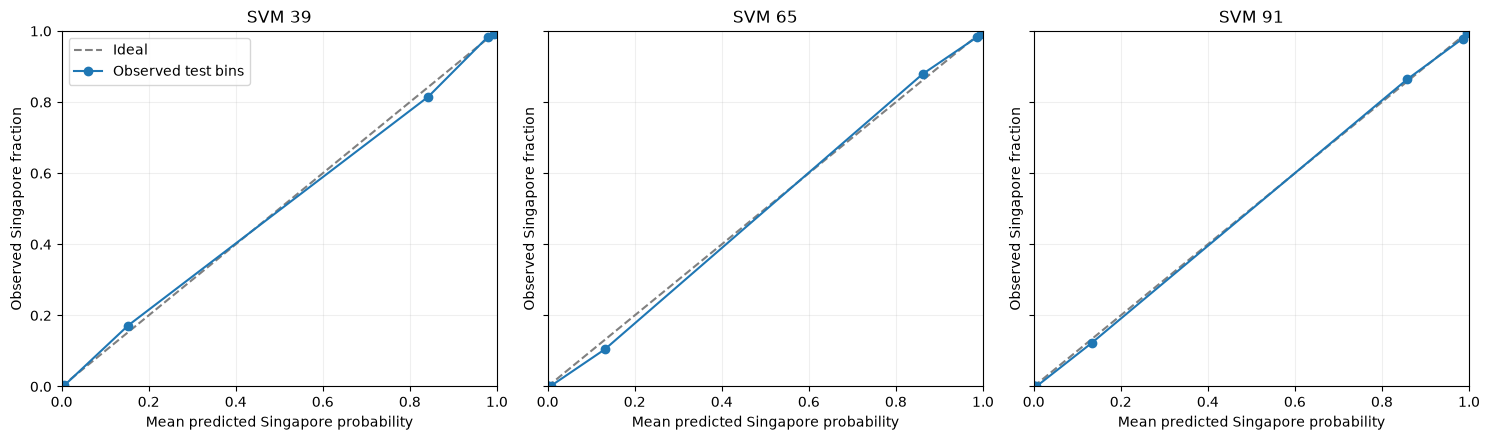

,feature_count,system,balanced_accuracy,singapore_recall,non_singapore_false_positive_rate,false_positive,false_negative,brier_score,log_loss
0,39,Original SVM,0.9615,0.9717,0.0486,150,86,NaN,NaN
1,39,Calibrated SVM at 0.50,0.9616,0.9680,0.0447,138,97,0.0288,0.1006
2,65,Original SVM,0.9736,0.9842,0.0370,114,48,NaN,NaN
3,65,Calibrated SVM at 0.50,0.9745,0.9782,0.0292,90,66,0.0208,0.0762
4,91,Original SVM,0.9731,0.9862,0.0399,123,42,NaN,NaN
5,91,Calibrated SVM at 0.50,0.9728,0.9796,0.0340,105,62,0.0207,0.0745


In [5]:
score_rows, outputs = [], []
fig, axes = plt.subplots(1, len(COUNTS), squeeze=False, figsize=(5 * len(COUNTS), 4.5), sharex=True, sharey=True)
for count, axis in zip(COUNTS, axes.ravel()):
    model = calibrated_models[count]
    source_features = features_by_count[count]
    result = predict_clip_probabilities(source_features[test_idx], model)
    result.insert(0, 'feature_count', count)
    result.insert(1, 'clip_id', clip_ids[test_idx])
    result.insert(2, 'speaker_group', groups[test_idx])
    result.insert(3, 'true_label', y[test_idx])
    raw_prediction = originals[count]['model'].predict(source_features[test_idx][:, originals[count]['columns']])
    result['original_svm_prediction'] = raw_prediction
    outputs.append(result)
    for name, prediction in [('Original SVM', raw_prediction),
                             ('Calibrated SVM at 0.50', result['predicted_class'].to_numpy())]:
        tn, fp, fn, tp = confusion_matrix(y[test_idx], prediction, labels=[0, 1]).ravel()
        calibrated = name.startswith('Calibrated')
        score_rows.append({'feature_count': count, 'system': name,
            'balanced_accuracy': balanced_accuracy_score(y[test_idx], prediction),
            'singapore_recall': tp / (tp + fn), 'non_singapore_false_positive_rate': fp / (tn + fp),
            'false_positive': int(fp), 'false_negative': int(fn),
            'brier_score': brier_score_loss(y[test_idx], result['p_singapore']) if calibrated else np.nan,
            'log_loss': log_loss(y[test_idx], result[['p_non_singapore', 'p_singapore']].to_numpy(), labels=[0, 1]) if calibrated else np.nan})
    fraction, mean_probability = calibration_curve(y[test_idx], result['p_singapore'], n_bins=10, strategy='quantile')
    axis.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    axis.plot(mean_probability, fraction, 'o-', label='Observed test bins')
    axis.set(title=f'SVM {count}', xlabel='Mean predicted Singapore probability',
             ylabel='Observed Singapore fraction', xlim=(0, 1), ylim=(0, 1))
    axis.grid(alpha=.2)
axes.ravel()[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'test_probability_reliability.png', dpi=180, bbox_inches='tight')
plt.show()
test_summary = pd.DataFrame(score_rows)
test_predictions = pd.concat(outputs, ignore_index=True)
display(test_summary.round(4))
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
test_predictions.to_csv(RESULTS_DIR / 'test_probability_predictions.csv', index=False)

## 5. Check saved models

Check that probabilities sum to one and reloaded models give the same classes.
At exactly 0.50, the helper chooses class 1; sklearn `predict()` chooses class 0.
Keep the feature-study model choice separate from these probability checks.

In [6]:
for count in COUNTS:
    model = joblib.load(RESULTS_DIR / f'svm_{count}_calibrated.joblib')
    source_features = features_by_count[count]
    rows = predict_clip_probabilities(source_features[test_idx], model)
    np.testing.assert_allclose(rows['p_singapore'] + rows['p_non_singapore'], 1.0)
    assert rows[['p_singapore', 'p_non_singapore']].ge(0).all().all()
    assert rows[['p_singapore', 'p_non_singapore']].le(1).all().all()
    direct = model.predict(source_features[test_idx][:, model.e1_probability_metadata_['columns']])
    not_tie = rows['p_singapore'].to_numpy() != 0.50
    np.testing.assert_array_equal(direct[not_tie], rows['predicted_class'].to_numpy()[not_tie])
    assert file_hash(STUDY_DIR / MODEL_PATHS[count]) == original_hashes[count]
    print(f'svm_{count}_calibrated.joblib: class/probability checks passed.')
print('Saved calibrated models, metadata, and test outputs:', RESULTS_DIR)
for path, original_hash in source_hashes.items():
    assert file_hash(path) == original_hash, f'Original study input changed: {path}'
print('Original studies, splits, metadata and feature caches are unchanged.')


svm_39_calibrated.joblib: class/probability checks passed.
svm_65_calibrated.joblib: class/probability checks passed.
svm_91_calibrated.joblib: class/probability checks passed.
Saved calibrated models, metadata, and test outputs: /home/mh/nusproj/E1_Feature_EngineeringV5/outputs/e1_feature_study_accent_40000_no_loudness_norm/svm_calibrated_probability_testing
Original studies, splits, metadata and feature caches are unchanged.
